In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.controllers import controller_a, controller_b, controller_plan
from src.dispatch import annual_bill
from src.config import TARIFF

fc = pd.read_csv(ROOT / "results" / "forecasts.csv", index_col=0, parse_dates=True)
pv = pd.read_csv(ROOT / "data" / "processed" / "pv_hourly.csv", index_col=0, parse_dates=True)["pv_kwh"]
load = pd.read_csv(ROOT / "data" / "processed" / "household_load_hourly.csv",
                   index_col=0, parse_dates=True)["load_kwh"]
spot = fc["price_actual_mwh"].values
svr72 = fc["price_forecast_mwh"].values
n_days = len(fc) / 24


def scenario(forecast=svr72, tariff=TARIFF, capacity=10.0, p_max=5.0, rt_eff=0.90):
    """Annual bills for controllers A to D under one set of assumptions."""
    eta = rt_eff ** 0.5
    bill = lambda r: annual_bill(r["import_kwh"], r["export_kwh"], spot, n_days, tariff)["total"]
    a = bill(controller_a(pv, load))
    b = bill(controller_b(pv, load, capacity=capacity, p_max=p_max, eta_c=eta, eta_d=eta))
    kw = dict(tariff=tariff, capacity=capacity, p_max=p_max, eta=eta)
    c = bill(controller_plan(pv, load, forecast, **kw))
    d = bill(controller_plan(pv, load, spot, **kw))
    return {"A": a, "B": b, "C": c, "D": d,
            "C saves vs B": b - c,
            "Error cost (C-D)": c - d,
            "C share of D saving (%)": 100 * (a - c) / (a - d),
            "C vs B room used (%)": 100 * (b - c) / (b - d) if b > d else np.nan}

In [2]:
t0 = time.time()
rows = {"Base case": scenario()}
for cap in [5, 15, 20]:
    rows[f"Battery {cap} kWh"] = scenario(capacity=cap)
for e in [0.80, 0.85, 0.95]:
    rows[f"Round-trip eff {int(e*100)}%"] = scenario(rt_eff=e)
for pw in [2.5, 7.5]:
    rows[f"Battery power {pw} kW"] = scenario(p_max=pw)
rows["Feed-in fixed 5 c/kWh"] = scenario(tariff={**TARIFF, "feed_in_mode": "fixed"})
for n in [10, 20]:
    rows[f"Network charge {n} c/kWh"] = scenario(tariff={**TARIFF, "network_other_c_kwh": float(n)})
for h in [96, 120]:
    wf = pd.read_csv(ROOT / "results" / f"walk_forward_h{h}.csv", index_col=0, parse_dates=True)
    rows[f"Forecast horizon {h} h"] = scenario(forecast=wf["SVR"].reindex(fc.index).values)

sens = pd.DataFrame(rows).T
sens.round(4).to_csv(ROOT / "results" / "sensitivity.csv")
print(f"{time.time() - t0:.0f} s")
sens.round(2)

49 s


,A,B,C,D,C saves vs B,Error cost (C-D),C share of D saving (%),C vs B room used (%)
Base case,1179.84,643.46,590.75,546.13,52.71,44.62,92.96,54.16
Battery 5 kWh,1179.84,820.15,805.04,769.56,15.10,35.48,91.35,29.86
Battery 15 kWh,1179.84,628.66,510.16,448.96,118.50,61.20,91.63,65.94
Battery 20 kWh,1179.84,623.05,463.37,391.03,159.68,72.33,90.83,68.82
Round-trip eff 80%,1179.84,668.84,633.25,590.21,35.59,43.04,92.70,45.26
Round-trip eff 85%,1179.84,655.37,611.87,567.94,43.50,43.93,92.82,49.76
Round-trip eff 95%,1179.84,632.29,569.65,524.32,62.63,45.34,93.08,58.01
Battery power 2.5 kW,1179.84,643.51,591.98,561.66,51.53,30.32,95.10,62.95
Battery power 7.5 kW,1179.84,643.46,590.90,535.20,52.56,55.70,91.36,48.55
Feed-in fixed 5 c/kWh,1000.76,548.50,530.93,517.80,17.57,13.13,97.28,57.23


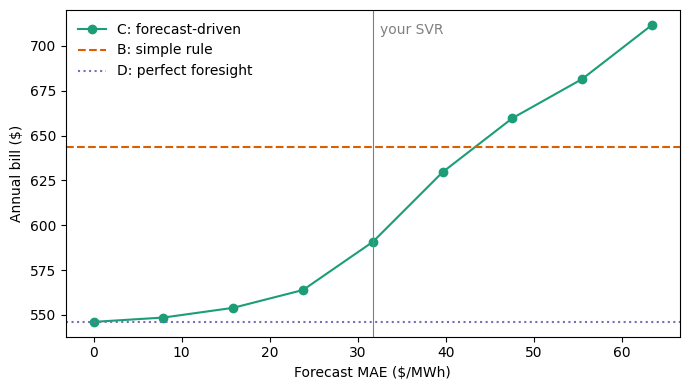

,Forecast MAE ($/MWh),C,Error cost (C-D),C saves vs B
Error multiplier,,,,
0.00,0.00,546.13,0.00,97.33
0.25,7.93,548.54,2.40,94.92
0.50,15.86,553.97,7.84,89.49
0.75,23.79,563.91,17.78,79.55
1.00,31.72,590.75,44.62,52.71
1.25,39.64,629.65,83.52,13.81
1.50,47.57,659.74,113.61,-16.28
1.75,55.50,681.59,135.46,-38.13
2.00,63.43,711.76,165.63,-68.30


In [3]:
sweep = []
for lam in np.arange(0, 2.01, 0.25):
    r = scenario(forecast=spot + lam * (svr72 - spot))
    r["Error multiplier"] = lam
    r["Forecast MAE ($/MWh)"] = np.abs(lam * (svr72 - spot)).mean()
    sweep.append(r)
sweep = pd.DataFrame(sweep).set_index("Error multiplier")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["Forecast MAE ($/MWh)"], sweep["C"], "o-", color="#1b9e77", label="C: forecast-driven")
ax.axhline(sweep["B"].iloc[0], color="#d95f02", ls="--", label="B: simple rule")
ax.axhline(sweep["D"].iloc[0], color="#7570b3", ls=":", label="D: perfect foresight")
ax.axvline(31.72, color="grey", lw=0.8)
ax.text(32.5, sweep["C"].max() - 5, "your SVR", color="grey")
ax.set_xlabel("Forecast MAE ($/MWh)")
ax.set_ylabel("Annual bill ($)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "results" / "fig_forecast_error_sweep.png", dpi=150)
plt.show()
sweep[["Forecast MAE ($/MWh)", "C", "Error cost (C-D)", "C saves vs B"]].round(2)